# VLA book renders 4 — diffusion process
Minimal notebook: load one episode and the π0 PyTorch checkpoint, run the denoising loop for one frame,
and render every step two ways — viridis grids and joint time series.

In [1]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from PIL import Image
from datasets import load_dataset

import torch
from openpi.training import config as _config
from openpi.policies import policy_config as _policy_config
from openpi.models import model as _model
from openpi.models_pytorch.pi0_pytorch import make_att_2d_masks

## Config

In [2]:
EPISODE_IDX = 0
PROMPT = "uncap the pen"
checkpoint_dir = "/home/stephen/openpi/pi0_aloha_pen_uncap_pytorch"
save_dir = "/home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/3_vla/graphics"
diff_dir = save_dir + "/diffusion"
os.makedirs(diff_dir, exist_ok=True)

USE_TEX = True             # LaTeX text rendering, as in vla_book_renders_1
mpl.rcParams['text.usetex'] = USE_TEX

# --- denoising run ---
DIFF_FRAME     = 50       # episode frame to condition on
DIFF_NUM_STEPS = 10        # Euler steps from t=1 (pure noise) to t=0 (actions); 10 is pi0's default
DIFF_SEED      = 42        # noise seed (same fixed noise as the other notebooks)
DIFF_SPACE     = "robot"   # "robot": each state converted to robot units, 14 joints (what pi0 would output)
                           # "model": raw normalized values the network works in (first 14 of 32 dims)

# --- style ---
CHILL_BROWN = '#948979'
labels_all = ["L Waist", "L Shoulder", "L Elbow", "L Forearm", "L Wrist angle", "L Wrist rotate", "L Gripper",
              "R Waist", "R Shoulder", "R Elbow", "R Forearm", "R Wrist angle", "R Wrist rotate", "R Gripper"]
COLORS = [
    "#D4382F",  # red
    "#D48239",  # orange
    "#9F8E7C",  # warm gray
    "#72573E",  # brown
    "#DBCEB9",  # tan
    "#F7F1E2",  # cream
    "#FCCB42",  # yellow
    "#469A4E",  # green
    # "#263D3F",  # dark teal
    "#68B1BC",  # light teal
    "#286C97",  # blue
    "#4C6274",  # slate blue
    "#BFCCE9",  # light blue
    "#865E79",  # purple
    "#EA5B77",  # pink
    "#6B3633",  # maroon
]

def style_ax(ax, color=CHILL_BROWN):
    ax.spines[:].set_color(color)
    ax.tick_params(colors=color, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    ax.title.set_color(color)

def style_cbar(cbar, color=CHILL_BROWN):
    cbar.outline.set_edgecolor(color)
    cbar.ax.tick_params(colors=color, which='both')
    cbar.ax.yaxis.label.set_color(color)
    cbar.ax.xaxis.label.set_color(color)
    cbar.ax.title.set_color(color)

## Load episode + model

In [3]:
ds = load_dataset("physical-intelligence/aloha_pen_uncap_diverse", split="train")
episode = ds.select(np.where(np.array(ds["episode_index"]) == EPISODE_IDX)[0])
print(f"{episode.num_rows} frames")

policy = _policy_config.create_trained_policy(_config.get_config("pi0_aloha_pen_uncap"), checkpoint_dir)
pt_model = policy._model
device = torch.device(policy._pytorch_device)
pt_model.paligemma_with_expert.paligemma.language_model.config._attn_implementation = "eager"
pt_model.paligemma_with_expert.gemma_expert.model.config._attn_implementation = "eager"

def frame_to_obs(frame):
    to_chw = lambda img: np.array(img).transpose(2, 0, 1)   # PIL HWC -> CHW
    return {
        "images": {cam: to_chw(frame[f"observation.images.{cam}"])
                   for cam in ["cam_high", "cam_left_wrist", "cam_right_wrist"]},
        "state": np.array(frame["observation.state"]),
        "prompt": PROMPT,
    }

Resolving data files:   0%|          | 0/123 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/123 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/123 [00:00<?, ?it/s]

300 frames


## 1. Run the denoising loop
Keeps every intermediate state: `diff_traj[i]` is the 50-step action chunk after `i` Euler steps (`i = 0` is pure noise).

In [4]:
def _batched(x):
    if isinstance(x, dict):
        return {k: _batched(v) for k, v in x.items()}
    return torch.from_numpy(np.array(x)).to(device)[None, ...]

# _obs = frame_to_obs(episode[DIFF_FRAME])
# _inputs = policy._input_transform(_obs)
_inputs = policy._input_transform(frame_to_obs(episode[DIFF_FRAME])) #SW

_observation = _model.Observation.from_dict(_batched(_inputs))
_images, _img_masks, _lang_tokens, _lang_masks, _state = pt_model._preprocess_observation(_observation, train=False)

diff_noise = np.random.RandomState(DIFF_SEED).randn(50, 32).astype(np.float32)   # (action horizon, model action dim)

with torch.no_grad():
    # images + prompt go through PaliGemma once; the action expert reuses that cache at every step
    _pre_embs, _pre_pad, _pre_att = pt_model.embed_prefix(_images, _img_masks, _lang_tokens, _lang_masks)
    _att_4d = pt_model._prepare_attention_masks_4d(make_att_2d_masks(_pre_pad, _pre_att))
    _, _kv_cache = pt_model.paligemma_with_expert.forward(
        attention_mask=_att_4d, position_ids=torch.cumsum(_pre_pad, dim=1) - 1,
        past_key_values=None, inputs_embeds=[_pre_embs, None], use_cache=True)

    x_t = torch.from_numpy(diff_noise).to(device)[None, ...]      # [1, 50, 32]
    dt, t = -1.0 / DIFF_NUM_STEPS, 1.0
    diff_ts, diff_traj_model = [t], [x_t[0].float().cpu().numpy().copy()]
    for _ in range(DIFF_NUM_STEPS):
        timestep = torch.tensor(t, dtype=torch.float32, device=device).expand(1)
        v_t = pt_model.denoise_step(_state, _pre_pad, _kv_cache, x_t, timestep)
        x_t = x_t + dt * v_t
        t += dt
        diff_ts.append(round(t, 6))
        diff_traj_model.append(x_t[0].float().cpu().numpy().copy())

diff_traj_model = np.array(diff_traj_model)                        # (steps+1, 50, 32)

def _to_robot(x):
    """Model-space actions (50, 32) -> robot units (50, 14), via the policy's own output transforms."""
    out = policy._output_transform({"state": np.array(_inputs["state"]).copy(), "actions": x.copy()})
    return np.asarray(out["actions"])

diff_traj_robot = np.array([_to_robot(x) for x in diff_traj_model])   # (steps+1, 50, 14)
diff_traj = diff_traj_robot if DIFF_SPACE == "robot" else diff_traj_model[:, :, :14]

# sanity check: the last state should equal what policy.infer returns for the same noise
# _ref = policy.infer(_obs, noise=diff_noise)["actions"]
_ref = policy.infer(frame_to_obs(episode[DIFF_FRAME]), noise=diff_noise)["actions"]
print(f"trajectory {diff_traj.shape} in {DIFF_SPACE} space, t = {diff_ts[0]} ... {diff_ts[-1]}")
print(f"max diff of final state vs policy.infer: {np.abs(diff_traj_robot[-1] - _ref).max():.2e}  (expect ~1e-3 or less)")

trajectory (11, 50, 14) in robot space, t = 1.0 ... 0.0
max diff of final state vs policy.infer: 1.66e-03  (expect ~1e-3 or less)


## 2. Viridis grids
One 14 x 50 image per step: rows are joints, columns are time within the action chunk.

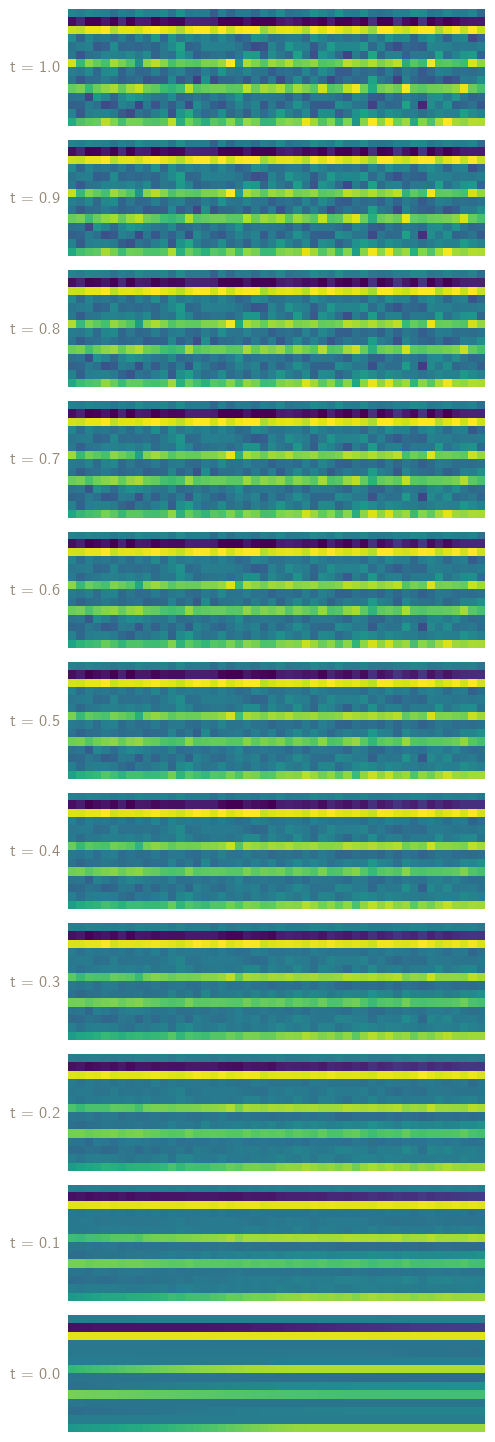

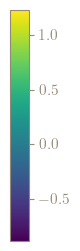

In [5]:
DIFF_CMAP        = "viridis"
DIFF_CLIM        = "shared"   # "shared": one color scale for every step (so steps are comparable)
                              # "per_step": each image scaled to its own min/max (as in p51)
                              # or a (vmin, vmax) tuple
DIFF_CLIM_PCT    = (1, 99)    # shared scale = these percentiles over all steps
DIFF_CELL_PX     = 24         # pixels per grid cell in the saved PNGs (50*24 x 14*24 = 1200 x 336)
DIFF_SHOW_STEPS  = None       # None = every step, or a list of step indices e.g. [0, 2, 4, 6, 8, 10]

_steps = list(range(len(diff_traj))) if DIFF_SHOW_STEPS is None else list(DIFF_SHOW_STEPS)
_cmap = plt.get_cmap(DIFF_CMAP)

def _clim(i):
    if DIFF_CLIM == "per_step":
        return float(diff_traj[i].min()), float(diff_traj[i].max())
    if DIFF_CLIM == "shared":
        return tuple(np.percentile(diff_traj, DIFF_CLIM_PCT))
    return tuple(DIFF_CLIM)

# one pixel-exact PNG per step
for i in _steps:
    vmin, vmax = _clim(i)
    rgba = _cmap(np.clip((diff_traj[i].T - vmin) / (vmax - vmin), 0, 1))               # (14, 50, 4)
    rgba = (255 * rgba).round().astype(np.uint8).repeat(DIFF_CELL_PX, axis=0).repeat(DIFF_CELL_PX, axis=1)
    Image.fromarray(rgba).save(f"{diff_dir}/grid_step{i:02d}_t{diff_ts[i]:.2f}.png")

# overview: all steps stacked, noise at the top
fig, axes = plt.subplots(len(_steps), 1, figsize=(8, 0.75 * 8 * 14 / 50 * len(_steps)), squeeze=False)
for ax, i in zip(axes[:, 0], _steps):
    vmin, vmax = _clim(i)
    ax.imshow(diff_traj[i].T, cmap=_cmap, vmin=vmin, vmax=vmax, interpolation="nearest", aspect="equal")
    ax.axis("off")
    ax.text(-0.02, 0.5, f"t = {diff_ts[i]:.1f}", transform=ax.transAxes, ha="right", va="center",
            color=CHILL_BROWN, fontsize=12)
fig.subplots_adjust(hspace=0.12)
fig.savefig(f"{diff_dir}/grid_overview.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()

# standalone colorbar (only meaningful when the scale is shared)
if DIFF_CLIM != "per_step":
    vmin, vmax = _clim(0)
    fig, ax = plt.subplots(figsize=(0.25, 3))
    cbar = fig.colorbar(ScalarMappable(norm=Normalize(vmin, vmax), cmap=_cmap), cax=ax)
    cbar.ax.tick_params(labelsize=11)
    style_cbar(cbar)
    for ext in ("png", "svg"):
        fig.savefig(f"{diff_dir}/grid_colorbar.{ext}", dpi=300, transparent=True, bbox_inches="tight")
    plt.show()

## 3. Time series
The 14 joint trajectories at each step, styled like the control-signal figure.

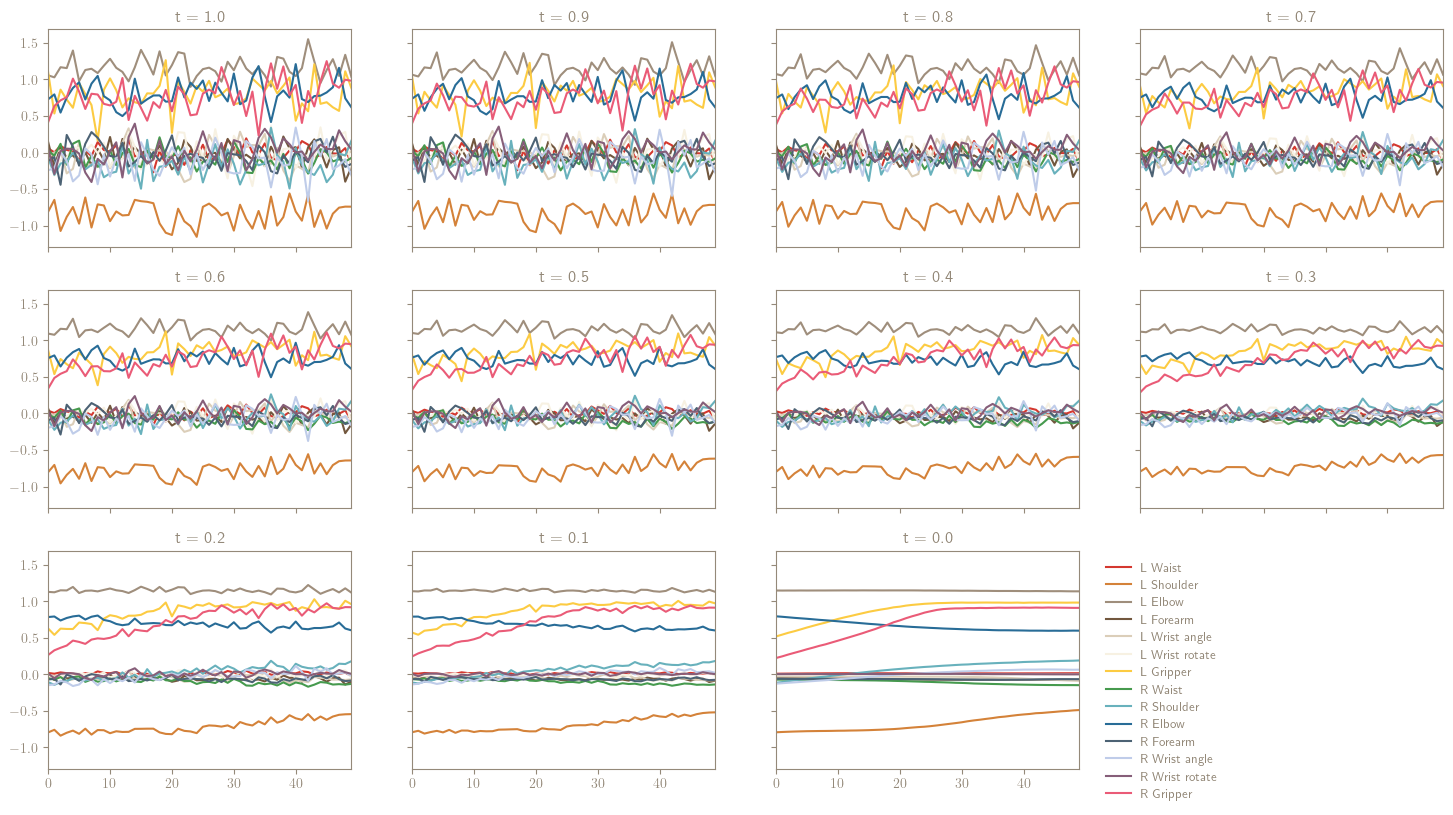

saved 11 time-series figures to /home/stephen/Stephencwelch Dropbox/welch_labs/ai_book_vol_2/3_vla/graphics/diffusion


In [12]:
DIFF_JOINTS      = list(range(14))   # which joints to draw
DIFF_TS_FIGSIZE  = (8, 2)
DIFF_LINEWIDTH   = 4.2
DIFF_FONTSIZE    = 18
DIFF_YLIM        = None              # None = one range covering every step (so panels are comparable), or (lo, hi)
DIFF_SHOW_LEGEND = False             # legend on each saved figure
DIFF_TS_STEPS    = None              # None = every step, or a list of step indices

_steps = list(range(len(diff_traj))) if DIFF_TS_STEPS is None else list(DIFF_TS_STEPS)
if DIFF_YLIM is None:
    _lo, _hi = diff_traj[:, :, DIFF_JOINTS].min(), diff_traj[:, :, DIFF_JOINTS].max()
    _ylim = (_lo - 0.05 * (_hi - _lo), _hi + 0.05 * (_hi - _lo))
else:
    _ylim = DIFF_YLIM

def _draw(ax, i, fontsize, linewidth):
    for j in DIFF_JOINTS:
        ax.plot(diff_traj[i][:, j], linewidth=linewidth, label=labels_all[j], color=COLORS[j % len(COLORS)])
    ax.set_xlim(0, diff_traj.shape[1] - 1)
    ax.set_ylim(*_ylim)
    ax.tick_params(labelsize=fontsize)
    style_ax(ax)

# one figure per step
for i in _steps:
    fig, ax = plt.subplots(figsize=DIFF_TS_FIGSIZE)
    _draw(ax, i, DIFF_FONTSIZE, DIFF_LINEWIDTH)
    # ax.set_xlabel("Step in action chunk", fontsize=DIFF_FONTSIZE)
    style_ax(ax)
    plt.xticks([])
    plt.yticks([])
    
    if DIFF_SHOW_LEGEND:
        ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=DIFF_FONTSIZE * 0.75,
                  frameon=False, labelcolor=CHILL_BROWN)
    for ext in ("png", "svg"):
        fig.savefig(f"{diff_dir}/timeseries_step{i:02d}_t{diff_ts[i]:.2f}.{ext}", dpi=300,
                    transparent=True, bbox_inches="tight")
    plt.close(fig)

# overview: every step side by side for review
_ncols = min(4, len(_steps))
_nrows = -(-len(_steps) // _ncols)
fig, axes = plt.subplots(_nrows, _ncols, figsize=(4.5 * _ncols, 3.2 * _nrows), squeeze=False, sharex=True, sharey=True)
for ax in axes.ravel()[len(_steps):]:
    ax.axis("off")
for ax, i in zip(axes.ravel(), _steps):
    _draw(ax, i, 10, 1.5)
    ax.set_title(f"t = {diff_ts[i]:.1f}", fontsize=12, color=CHILL_BROWN)
axes.ravel()[len(_steps) - 1].legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9,
                                     frameon=False, labelcolor=CHILL_BROWN)
fig.savefig(f"{diff_dir}/timeseries_overview.png", dpi=200, transparent=True, bbox_inches="tight")
plt.show()
print(f"saved {len(_steps)} time-series figures to {diff_dir}")

In [13]:
# Standalone legend for the time-series figures
from matplotlib.lines import Line2D

LEGEND_NCOLS = 1    # 1 = single column; 2 puts left arm and right arm side by side; 7 or 14 for a horizontal strip

handles = [Line2D([0], [0], color=COLORS[j % len(COLORS)], linewidth=DIFF_LINEWIDTH, label=labels_all[j])
           for j in DIFF_JOINTS]

fig = plt.figure(figsize=(1, 1))
legend = fig.legend(handles=handles, loc="center", ncols=LEGEND_NCOLS, frameon=False,
                    fontsize=DIFF_FONTSIZE * 0.75, labelcolor=CHILL_BROWN)
for ext in ("svg", "png"):
    fig.savefig(f"{diff_dir}/timeseries_legend.{ext}", dpi=300, transparent=True,
                bbox_inches="tight", pad_inches=0.05)
plt.show()

<Figure size 100x100 with 0 Axes>